# 🏠 House Prices — Feature Engineering Avanzado

> **Kaggle Competition** | Chalito · LYONSOFT PERU
> Este notebook construye, valida y selecciona cada feature nueva con evidencia cuantitativa.

---
### Estructura
```
1.  Setup y carga del dataset limpio
2.  Features de ÁREA TOTAL
3.  Features de CALIDAD COMPUESTA
4.  Features de ANTIGÜEDAD y TIEMPO
5.  Features de BAÑOS
6.  Features BINARIAS (tiene / no tiene)
7.  Features de INTERACCIÓN (calidad × área)
8.  Target Encoding de Neighborhood (K-Fold, sin leakage)
9.  Features POLINÓMICAS y LOG
10. Validación cuantitativa — impacto de cada grupo de features
11. Guardado de artefactos
```

In [41]:
# ─── 0. IMPORTACIONES ───────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import skew, pearsonr
from matplotlib.patches import Patch
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import RobustScaler
import joblib

plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': 'white',
    'axes.facecolor': '#f8f9fa',
    'axes.grid': True, 'grid.alpha': 0.35,
    'axes.spines.top': False, 'axes.spines.right': False,
})

COLOR_MAIN    = '#2563EB'
COLOR_ACCENT  = '#F59E0B'
COLOR_DANGER  = '#EF4444'
COLOR_SUCCESS = '#10B981'
COLOR_PURPLE  = '#7C3AED'

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', '{:.4f}'.format)
print('✅ Setup completo')

✅ Setup completo


---
## 1 · Carga del dataset limpio
> Partimos del dataset ya imputado (resultado del notebook de preprocesamiento).

In [42]:
# ─── 1.1 CARGA + IMPUTACIÓN BASE ───────────────────────────────────────────
train_raw = pd.read_csv('../data/train.csv')
test_raw  = pd.read_csv('../data/test.csv')

# Eliminar outliers críticos (GrLivArea > 4000 sqft son outliers conocidos)
outlier_mask = train_raw['GrLivArea'] > 4000  # & (train_raw['SalePrice'] < 300_000)
train_raw = train_raw[~outlier_mask].reset_index(drop=True)
ntrain = len(train_raw)

# Target log1p
y = np.log1p(train_raw['SalePrice'])

# Merge para procesar juntos
all_data = pd.concat([train_raw.drop('SalePrice', axis=1), test_raw], axis=0, ignore_index=True)
all_data.drop('Id', axis=1, inplace=True)

# ── Imputación rápida ───────────────────────────────────────────────────────
none_cols = ['PoolQC','MiscFeature','Alley','Fence','FireplaceQu',
             'GarageType','GarageFinish','GarageQual','GarageCond',
             'BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2','MasVnrType']
zero_cols = ['GarageYrBlt','GarageArea','GarageCars','BsmtFinSF1','BsmtFinSF2',
             'BsmtUnfSF','TotalBsmtSF','BsmtFullBath','BsmtHalfBath','MasVnrArea']
for col in none_cols:
    if col in all_data.columns: all_data[col].fillna('None', inplace=True)
for col in zero_cols:
    if col in all_data.columns: all_data[col].fillna(0, inplace=True)

# LotFrontage: mediana por vecindario + fallback global
all_data['LotFrontage'] = all_data.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median()))
if all_data['LotFrontage'].isna().any():
    all_data['LotFrontage'].fillna(all_data['LotFrontage'].median(), inplace=True)

# Resto de object → moda (con fallback 'None')
for col in all_data.select_dtypes('object').columns:
    if all_data[col].isna().any():
        mode_val = all_data[col].mode()
        fill_val = mode_val[0] if len(mode_val) else 'None'
        all_data[col].fillna(fill_val, inplace=True)

# Resto de numéricos → mediana (con fallback 0)
for col in all_data.select_dtypes([np.number]).columns:
    if all_data[col].isna().any():
        med = all_data[col].median()
        all_data[col].fillna(med if not np.isnan(med) else 0, inplace=True)

# 🔒 RED DE SEGURIDAD FINAL: forzar 0 en cualquier NaN residual
all_data = all_data.fillna(0)

# Encoding ordinal de calidades para el evaluador Ridge
quality_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
for col in ['ExterQual','ExterCond','BsmtQual','BsmtCond','HeatingQC',
            'KitchenQual','FireplaceQu','GarageQual','GarageCond']:
    if col in all_data.columns:
        all_data[col] = all_data[col].map(quality_map).fillna(0)

# Score BASE (sin features nuevas) para comparar despues
_all_dummies_base = pd.get_dummies(all_data.copy(), drop_first=False, dtype=int)
_X_base = _all_dummies_base.iloc[:ntrain].values

sc0 = RobustScaler()
kf0 = KFold(n_splits=10, shuffle=True, random_state=42)
base_scores = np.sqrt(-cross_val_score(
    Ridge(alpha=10), sc0.fit_transform(_X_base), y,
    scoring='neg_mean_squared_error', cv=kf0
))
BASE_RMSLE = base_scores.mean()

print(f'Dataset cargado: {all_data.shape}  |  nulos: {all_data.isnull().sum().sum()}')
print(f'ntrain={ntrain}  |  y shape={y.shape}')
print(f'\n📊 RMSLE BASE (sin FE): {BASE_RMSLE:.5f} ± {base_scores.std():.5f}')

Dataset cargado: (2915, 79)  |  nulos: 0
ntrain=1456  |  y shape=(1456,)

📊 RMSLE BASE (sin FE): 0.11291 ± 0.01366


---
## 2 · Features de Área Total
> Las casas se valoran por superficie habitable. Combinamos sótano + planta baja + segunda planta.

📐 Features de ÁREA — correlación con log(SalePrice):
   TotalSF                 r = +0.8220
   TotalAbvGrdSF           r = +0.7294
   TotalPorchSF            r = +0.1987
   BsmtToTotalRatio        r = +0.0680
   SecFloorRatio           r = +0.1639
   LotDensity              r = -0.0017


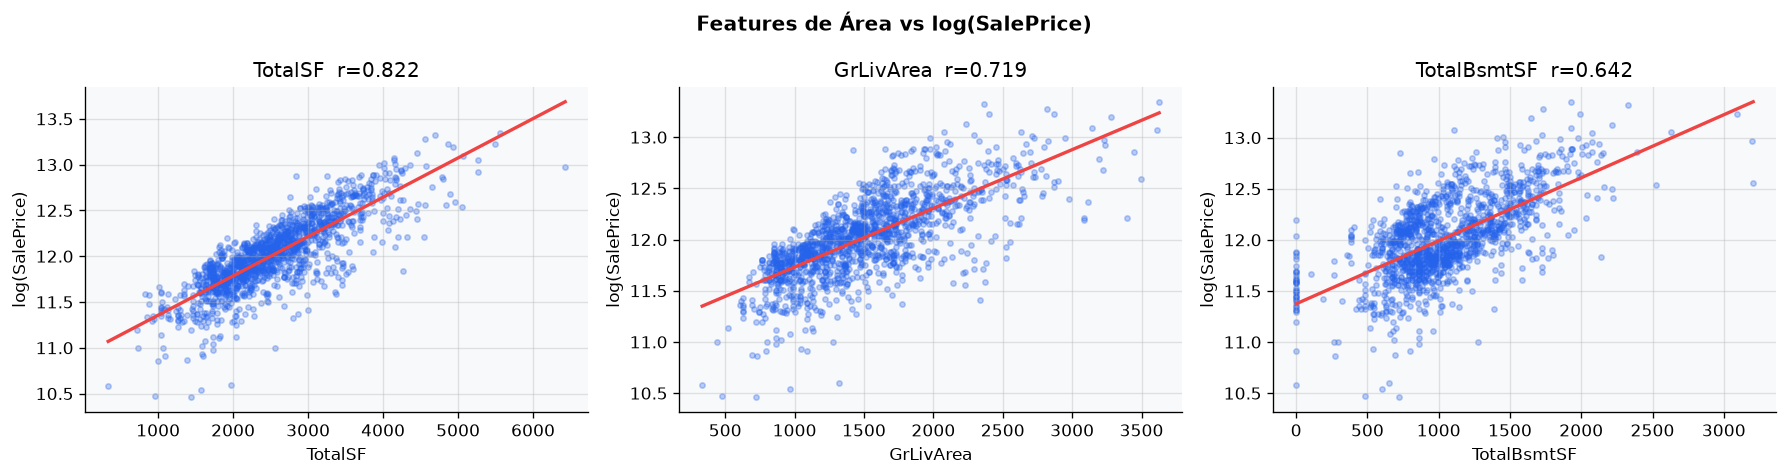

In [43]:
# ─── 2.1 FEATURES DE ÁREA ──────────────────────────────────────────────────
all_data['TotalSF']         = all_data['TotalBsmtSF'] + all_data['1stFlrSF'] + all_data['2ndFlrSF']
all_data['TotalAbvGrdSF']   = all_data['1stFlrSF'] + all_data['2ndFlrSF']
all_data['TotalPorchSF']    = (all_data['OpenPorchSF'] + all_data['EnclosedPorch'] +
                                all_data['3SsnPorch'] + all_data['ScreenPorch'])
all_data['BsmtToTotalRatio']= np.where(all_data['TotalSF'] > 0,
                                all_data['TotalBsmtSF'] / all_data['TotalSF'], 0)
all_data['SecFloorRatio']   = np.where(all_data['GrLivArea'] > 0,
                                all_data['2ndFlrSF'] / all_data['GrLivArea'], 0)
all_data['LotDensity']      = np.where(all_data['LotArea'] > 0,
                                all_data['GrLivArea'] / all_data['LotArea'], 0)

area_feats = ['TotalSF','TotalAbvGrdSF','TotalPorchSF','BsmtToTotalRatio','SecFloorRatio','LotDensity']
print('📐 Features de ÁREA — correlación con log(SalePrice):')
for f in area_feats:
    r, _ = pearsonr(all_data[f].iloc[:ntrain], y)
    print(f'   {f:<22}  r = {r:+.4f}')

# Scatter: TotalSF vs SalePrice
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Features de Área vs log(SalePrice)', fontweight='bold')
for ax, feat in zip(axes, ['TotalSF', 'GrLivArea', 'TotalBsmtSF']):
    x = all_data[feat].iloc[:ntrain]
    r, _ = pearsonr(x, y)
    ax.scatter(x, y, alpha=0.3, s=10, color=COLOR_MAIN)
    z = np.polyfit(x, y, 1)
    xr = np.linspace(x.min(), x.max(), 100)
    ax.plot(xr, np.poly1d(z)(xr), color=COLOR_DANGER, linewidth=2)
    ax.set_xlabel(feat); ax.set_ylabel('log(SalePrice)')
    ax.set_title(f'{feat}  r={r:.3f}')
plt.tight_layout()
plt.savefig('fe_01_area.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 3 · Features de Calidad Compuesta
> La calidad de una casa no es solo `OverallQual`. Combinamos varias dimensiones.

⭐ Features de CALIDAD COMPUESTA — correlación con log(SalePrice):
   QualityScore            r = +0.8495
   ConditionScore          r = +0.0570
   QualCondIndex           r = +0.7008
   TotalQualSF             r = +0.8835
   GrLivQual               r = +0.8387
   GarageScore             r = +0.6724


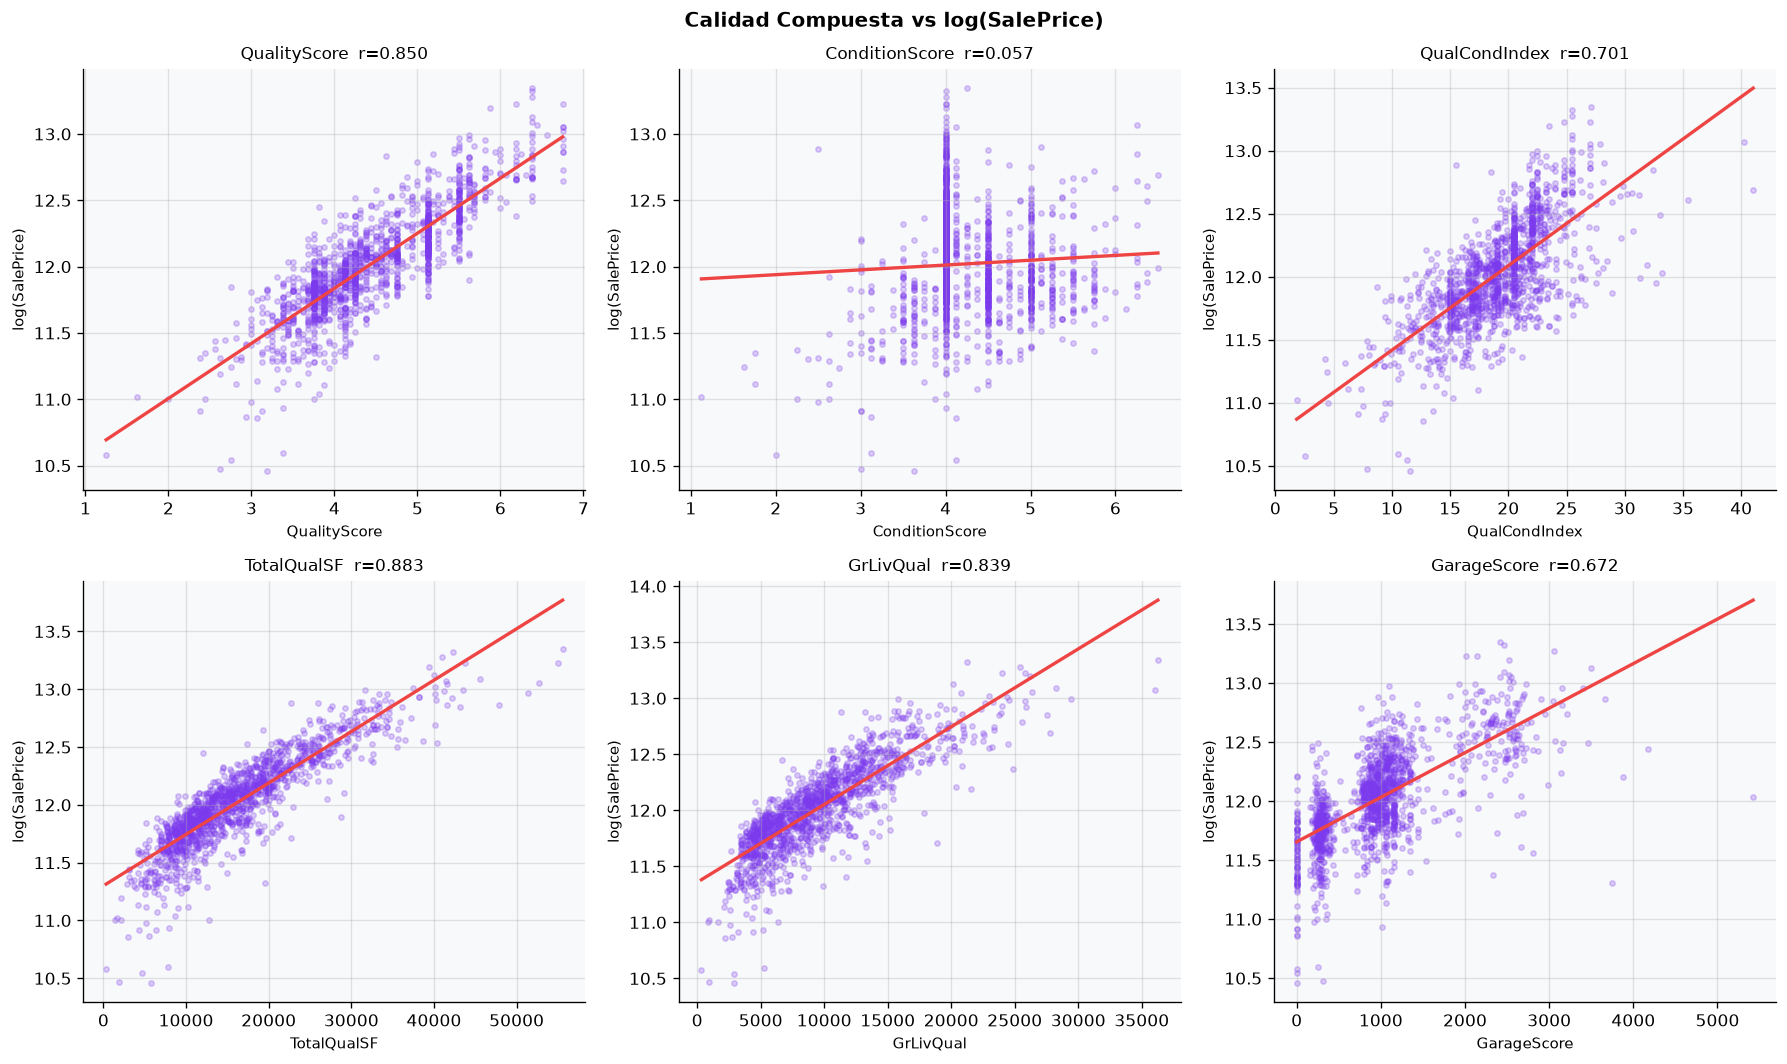

In [44]:
# ─── 3.1 SCORES DE CALIDAD COMPUESTA ───────────────────────────────────────
all_data['QualityScore']  = (all_data['OverallQual'] * 3.0 + all_data['ExterQual'] * 1.5 +
                              all_data['KitchenQual'] * 1.5 + all_data['BsmtQual'] * 1.0 +
                              all_data['GarageQual']  * 0.5 + all_data['HeatingQC'] * 0.5) / 8.0
all_data['ConditionScore']= (all_data['OverallCond'] * 2.0 + all_data['ExterCond'] * 1.0 +
                              all_data['GarageCond']  * 0.5 + all_data['BsmtCond']  * 0.5) / 4.0
all_data['QualCondIndex'] = all_data['QualityScore'] * all_data['ConditionScore']
all_data['TotalQualSF']   = all_data['OverallQual'] * all_data['TotalSF']
all_data['GrLivQual']     = all_data['GrLivArea']   * all_data['OverallQual']
all_data['GarageScore']   = all_data['GarageCars']  * all_data['GarageArea']

quality_feats = ['QualityScore','ConditionScore','QualCondIndex','TotalQualSF','GrLivQual','GarageScore']
print('⭐ Features de CALIDAD COMPUESTA — correlación con log(SalePrice):')
for f in quality_feats:
    r, _ = pearsonr(all_data[f].iloc[:ntrain], y)
    print(f'   {f:<22}  r = {r:+.4f}')

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.suptitle('Calidad Compuesta vs log(SalePrice)', fontweight='bold')
for ax, feat in zip(axes.ravel(), quality_feats):
    x = all_data[feat].iloc[:ntrain]
    r, _ = pearsonr(x, y)
    ax.scatter(x, y, alpha=0.25, s=10, color=COLOR_PURPLE)
    z = np.polyfit(x, y, 1)
    xr = np.linspace(x.min(), x.max(), 100)
    ax.plot(xr, np.poly1d(z)(xr), color=COLOR_DANGER, linewidth=2)
    ax.set_xlabel(feat, fontsize=9); ax.set_ylabel('log(SalePrice)', fontsize=9)
    ax.set_title(f'{feat}  r={r:.3f}', fontsize=10)
plt.tight_layout()
plt.savefig('fe_02_quality.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 4 · Features de Antigüedad y Tiempo
> La edad de la casa y cuándo fue remodelada tienen fuerte impacto en el precio.

⏳ Features TEMPORALES:
   HouseAge                r = -0.5896
   RemodAge                r = -0.5714
   EffectiveAge            r = -0.5714
   IsNew                   r = +0.2267
   WasRemodeled            r = -0.0751
   RemodRecent             r = +0.3707


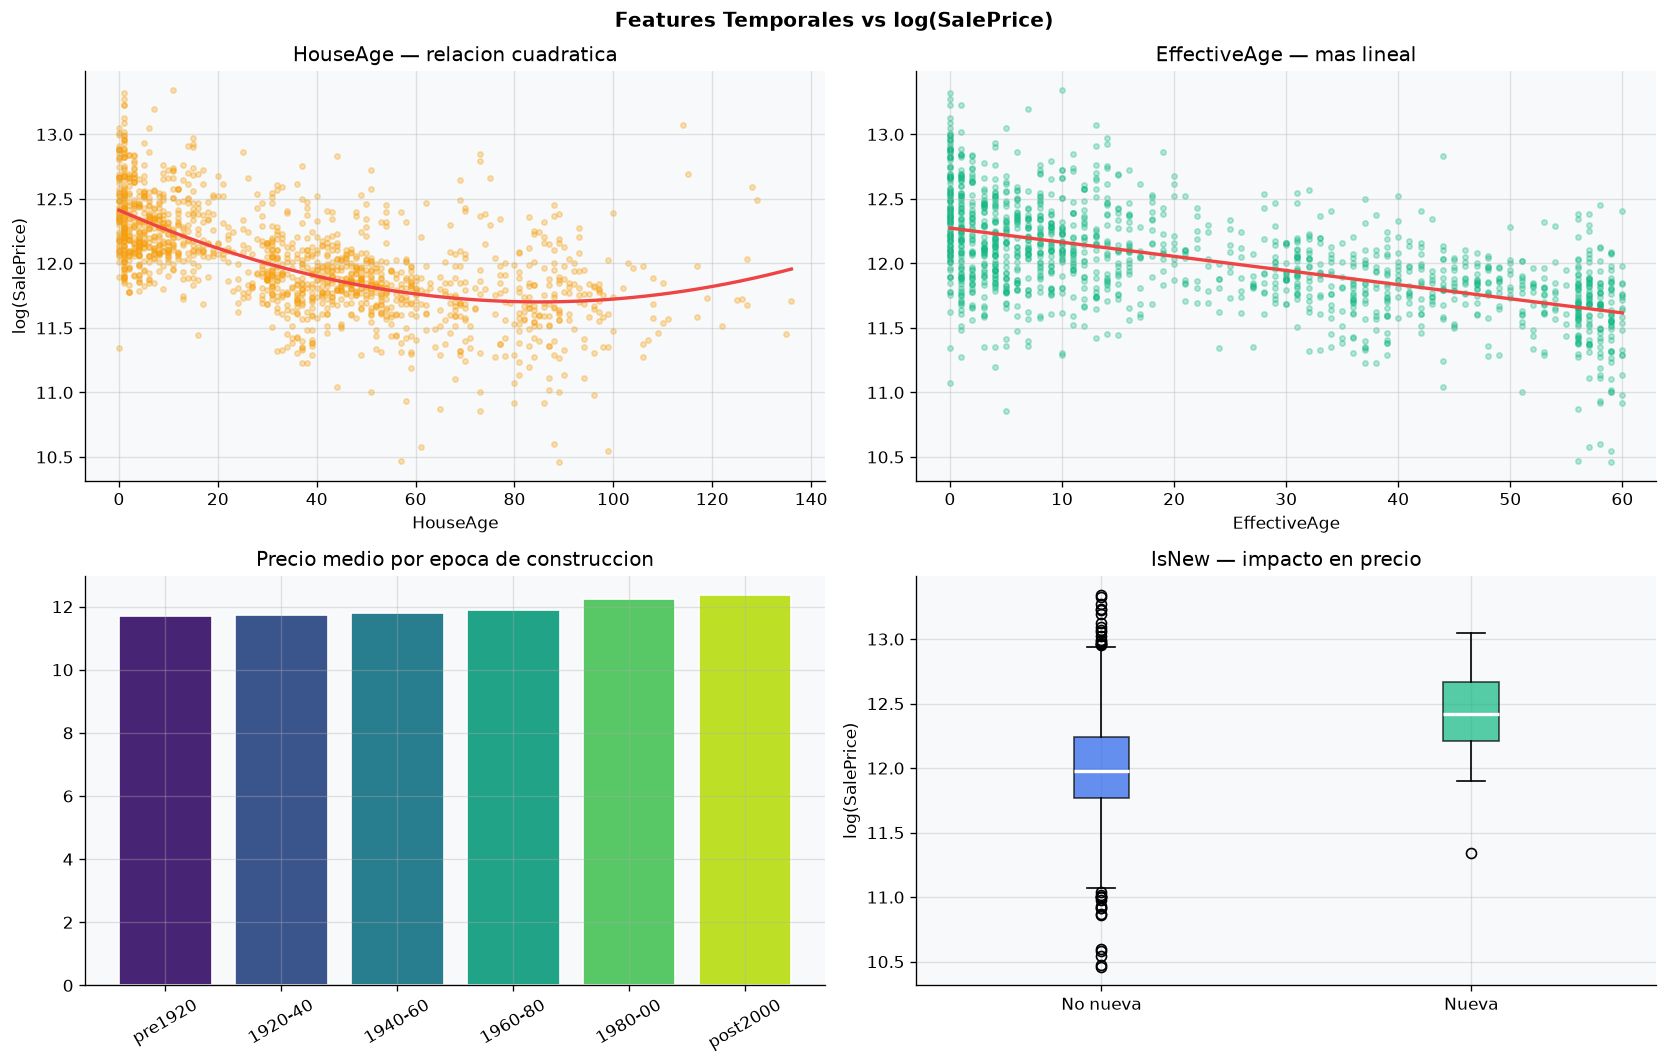

In [45]:
# ─── 4.1 FEATURES TEMPORALES ────────────────────────────────────────────────
all_data['HouseAge']     = all_data['YrSold'] - all_data['YearBuilt']
all_data['RemodAge']     = all_data['YrSold'] - all_data['YearRemodAdd']
all_data['GarageAge']    = np.where(all_data['GarageYrBlt'] > 0,
                            all_data['YrSold'] - all_data['GarageYrBlt'], all_data['HouseAge'])
all_data['IsNew']        = (all_data['YearBuilt'] == all_data['YrSold']).astype(int)
all_data['WasRemodeled'] = (all_data['YearRemodAdd'] != all_data['YearBuilt']).astype(int)
all_data['RemodRecent']  = (all_data['RemodAge'] <= 5).astype(int)
all_data['EffectiveAge'] = np.minimum(all_data['HouseAge'], all_data['RemodAge'])

# Época de construcción
bins   = [0, 1920, 1940, 1960, 1980, 2000, 2025]
labels = ['pre1920','1920-40','1940-60','1960-80','1980-00','post2000']
all_data['EraBuilt'] = pd.cut(all_data['YearBuilt'], bins=bins, labels=labels).astype(str)

print('⏳ Features TEMPORALES:')
for f in ['HouseAge','RemodAge','EffectiveAge','IsNew','WasRemodeled','RemodRecent']:
    r, _ = pearsonr(all_data[f].iloc[:ntrain].clip(lower=0), y)
    print(f'   {f:<22}  r = {r:+.4f}')

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Features Temporales vs log(SalePrice)', fontweight='bold')

ax = axes[0, 0]
x = all_data['HouseAge'].iloc[:ntrain].clip(lower=0)
ax.scatter(x, y, alpha=0.3, s=10, color=COLOR_ACCENT)
z = np.polyfit(x, y, 2)
xr = np.linspace(x.min(), x.max(), 200)
ax.plot(xr, np.poly1d(z)(xr), color=COLOR_DANGER, linewidth=2)
ax.set_xlabel('HouseAge'); ax.set_ylabel('log(SalePrice)')
ax.set_title('HouseAge — relacion cuadratica')

ax = axes[0, 1]
x2 = all_data['EffectiveAge'].iloc[:ntrain].clip(lower=0)
ax.scatter(x2, y, alpha=0.3, s=10, color=COLOR_SUCCESS)
z2 = np.polyfit(x2, y, 1)
xr2 = np.linspace(x2.min(), x2.max(), 100)
ax.plot(xr2, np.poly1d(z2)(xr2), color=COLOR_DANGER, linewidth=2)
ax.set_xlabel('EffectiveAge'); ax.set_title('EffectiveAge — mas lineal')

ax = axes[1, 0]
era_p = pd.DataFrame({'Era': all_data['EraBuilt'].iloc[:ntrain], 'y': y}).groupby('Era')['y'].mean().reindex(labels)
ax.bar(era_p.index, era_p.values, color=plt.cm.viridis(np.linspace(0.1,0.9,len(era_p))), edgecolor='white')
ax.set_title('Precio medio por epoca de construccion')
ax.tick_params(axis='x', rotation=30)

ax = axes[1, 1]
g0 = y[all_data['IsNew'].iloc[:ntrain] == 0].values
g1 = y[all_data['IsNew'].iloc[:ntrain] == 1].values
bp = ax.boxplot([g0, g1], patch_artist=True,
                medianprops=dict(color='white', linewidth=2))
bp['boxes'][0].set_facecolor(COLOR_MAIN); bp['boxes'][0].set_alpha(0.7)
bp['boxes'][1].set_facecolor(COLOR_SUCCESS); bp['boxes'][1].set_alpha(0.7)
ax.set_xticklabels(['No nueva','Nueva'])
ax.set_ylabel('log(SalePrice)'); ax.set_title('IsNew — impacto en precio')

plt.tight_layout()
plt.savefig('fe_03_time.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 5 · Features de Baños

In [46]:
# ─── 5.1 FEATURES DE BAÑOS ─────────────────────────────────────────────────
all_data['TotalBathrooms']  = (all_data['FullBath']     * 1.0 + all_data['HalfBath'] * 0.5 +
                                all_data['BsmtFullBath'] * 1.0 + all_data['BsmtHalfBath'] * 0.5)
all_data['AbvGrdBathrooms'] = all_data['FullBath'] + 0.5 * all_data['HalfBath']
all_data['BathRatio']       = np.where(all_data['TotRmsAbvGrd'] > 0,
                                all_data['TotalBathrooms'] / all_data['TotRmsAbvGrd'], 0)

print('Baños — correlación con log(SalePrice):')
for f in ['TotalBathrooms','AbvGrdBathrooms','BathRatio']:
    r, _ = pearsonr(all_data[f].iloc[:ntrain], y)
    print(f'   {f:<22}  r = {r:+.4f}')

Baños — correlación con log(SalePrice):
   TotalBathrooms          r = +0.6729
   AbvGrdBathrooms         r = +0.6362
   BathRatio               r = +0.3067


---
## 6 · Features Binarias — "Tiene / No tiene"

Binarias — impacto promedio en log(SalePrice):
   HasFireplace          delta = +0.4049 log$
   HasGarage             delta = +0.5613 log$
   HasBsmt               delta = +0.5051 log$
   Has2ndFloor           delta = +0.1169 log$
   HasPorch              delta = +0.2783 log$
   HasMasVnr             delta = +0.3111 log$
   HasWoodDeck           delta = +0.2524 log$
   HasPool               delta = +0.2743 log$


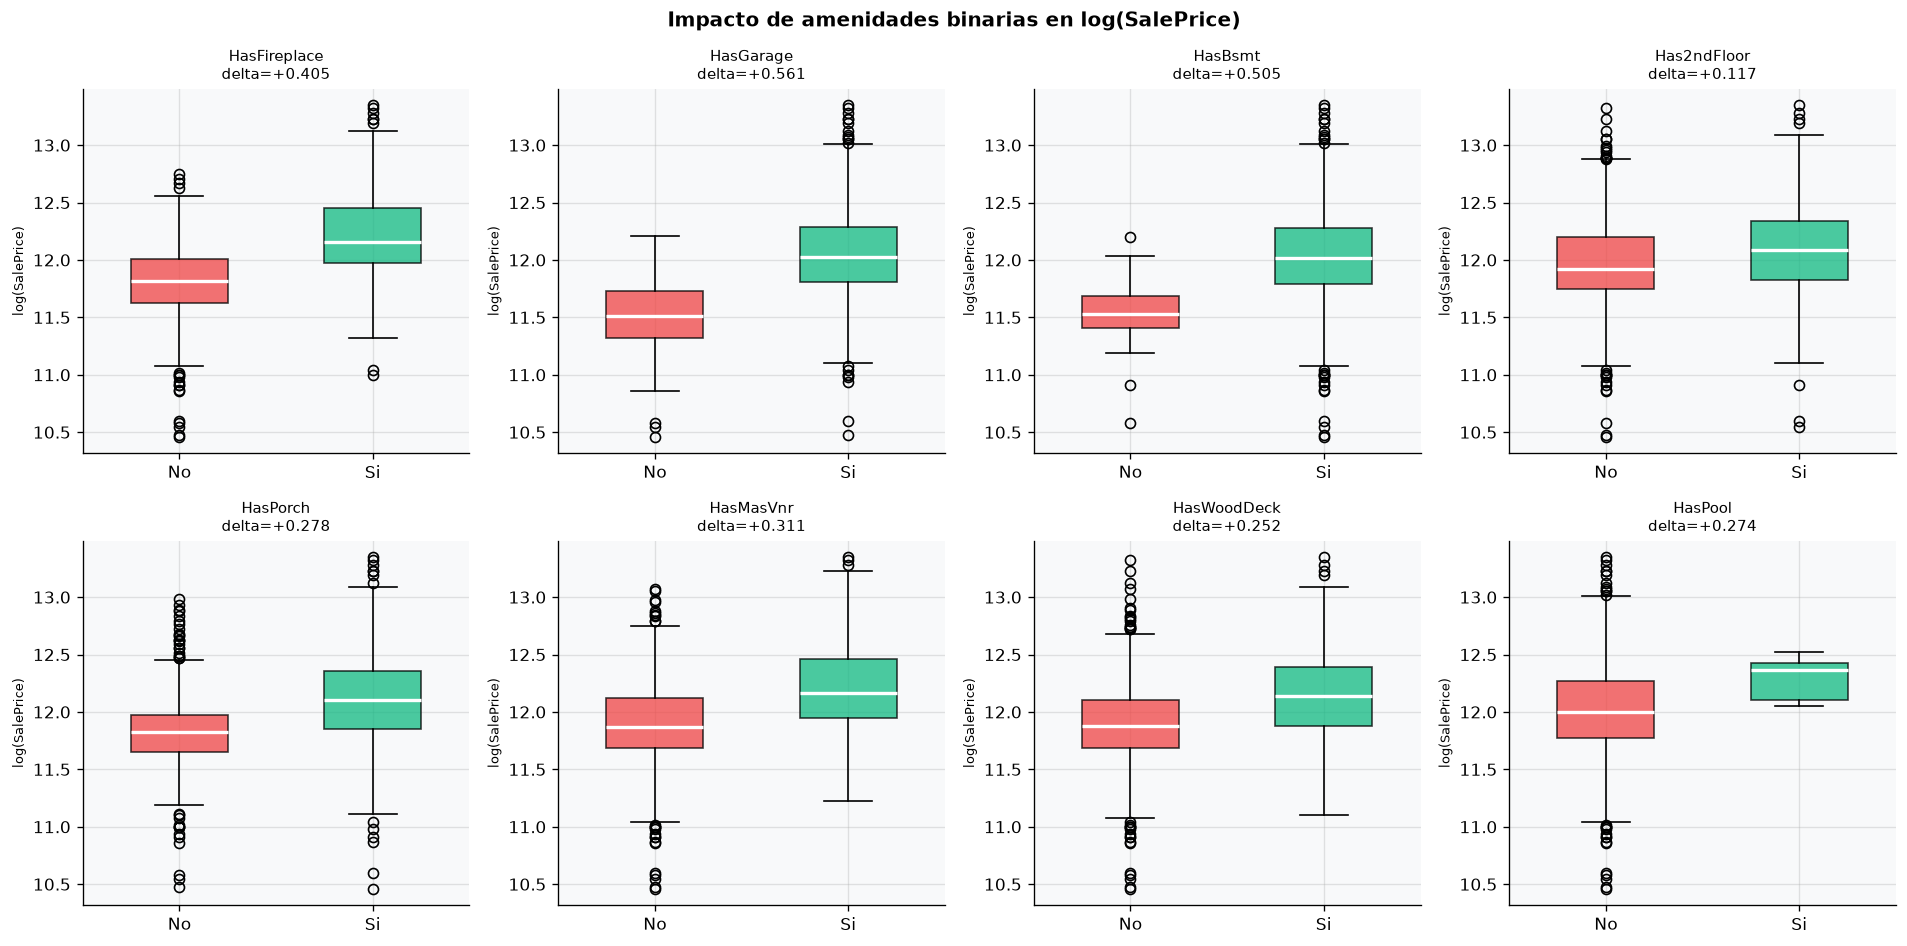

In [47]:
# ─── 6.1 FLAGS BINARIOS Y AMENITY SCORE ────────────────────────────────────
all_data['HasPool']      = (all_data['PoolArea']     > 0).astype(int)
all_data['HasGarage']    = (all_data['GarageArea']   > 0).astype(int)
all_data['HasBsmt']      = (all_data['TotalBsmtSF']  > 0).astype(int)
all_data['HasFireplace'] = (all_data['Fireplaces']   > 0).astype(int)
all_data['HasPorch']     = (all_data['TotalPorchSF'] > 0).astype(int)
all_data['Has2ndFloor']  = (all_data['2ndFlrSF']     > 0).astype(int)
all_data['HasMasVnr']    = (all_data['MasVnrArea']   > 0).astype(int)
all_data['HasWoodDeck']  = (all_data['WoodDeckSF']   > 0).astype(int)
all_data['AmenityScore'] = (all_data['HasPool'] * 3 + all_data['HasFireplace'] * 2 +
                             all_data['HasGarage'] * 2 + all_data['HasBsmt'] +
                             all_data['HasPorch'] + all_data['Has2ndFloor'] +
                             all_data['HasWoodDeck'] + all_data['HasMasVnr'])

binary_plot = ['HasFireplace','HasGarage','HasBsmt','Has2ndFloor',
               'HasPorch','HasMasVnr','HasWoodDeck','HasPool']
print('Binarias — impacto promedio en log(SalePrice):')
for f in binary_plot:
    g0 = y[all_data[f].iloc[:ntrain] == 0].mean()
    g1 = y[all_data[f].iloc[:ntrain] == 1].mean()
    print(f'   {f:<20}  delta = {g1-g0:+.4f} log$')

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Impacto de amenidades binarias en log(SalePrice)', fontweight='bold')
for ax, feat in zip(axes.ravel(), binary_plot):
    no_v  = y[all_data[feat].iloc[:ntrain] == 0].values
    yes_v = y[all_data[feat].iloc[:ntrain] == 1].values
    bp = ax.boxplot([no_v, yes_v], patch_artist=True,
                    medianprops=dict(color='white', linewidth=2), widths=0.5)
    bp['boxes'][0].set_facecolor(COLOR_DANGER)
    bp['boxes'][1].set_facecolor(COLOR_SUCCESS)
    for box in bp['boxes']: box.set_alpha(0.75)
    delta = yes_v.mean() - no_v.mean()
    ax.set_xticklabels(['No','Si'])
    ax.set_title(f'{feat}\ndelta={delta:+.3f}', fontsize=9)
    ax.set_ylabel('log(SalePrice)', fontsize=8)
plt.tight_layout()
plt.savefig('fe_04_binary.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 7 · Features de Interacción
> Multiplicaciones que el modelo lineal no puede descubrir solo.

In [48]:
# ─── 7.1 INTERACCIONES ESTRATÉGICAS ────────────────────────────────────────
all_data['OverallQual_TotalSF']    = all_data['OverallQual'] * all_data['TotalSF']
all_data['OverallQual_GrLivArea']  = all_data['OverallQual'] * all_data['GrLivArea']
all_data['OverallQual_YearBuilt']  = all_data['OverallQual'] * all_data['YearBuilt']
all_data['OverallQual_GarageCars'] = all_data['OverallQual'] * all_data['GarageCars']
all_data['TotalSF_YearBuilt']      = all_data['TotalSF']     * all_data['YearBuilt']
all_data['YearBuilt_QualSq']       = all_data['YearBuilt']   * (all_data['OverallQual'] ** 2)
all_data['TotRms_Qual']            = all_data['TotRmsAbvGrd']* all_data['OverallQual']

interact_feats = ['OverallQual_TotalSF','OverallQual_GrLivArea','OverallQual_YearBuilt',
                  'OverallQual_GarageCars','TotalSF_YearBuilt','YearBuilt_QualSq','TotRms_Qual']
print('⚡ Interacciones — correlación con log(SalePrice):')
for f in interact_feats:
    r, _ = pearsonr(all_data[f].iloc[:ntrain], y)
    print(f'   {f:<32}  r = {r:+.4f}')

⚡ Interacciones — correlación con log(SalePrice):
   OverallQual_TotalSF               r = +0.8835
   OverallQual_GrLivArea             r = +0.8387
   OverallQual_YearBuilt             r = +0.8260
   OverallQual_GarageCars            r = +0.8152
   TotalSF_YearBuilt                 r = +0.8363
   YearBuilt_QualSq                  r = +0.8187
   TotRms_Qual                       r = +0.7916


---
## 8 · Target Encoding de Neighborhood (K-Fold, sin leakage)
> `Neighborhood` es una de las variables más poderosas. El target encoding captura la información ordinal que OHE pierde.

  Neighborhood_TargetEnc               r = +0.7369
  MSSubClass_TargetEnc                 r = +0.5601
  MSZoning_TargetEnc                   r = +0.3997
  SaleType_TargetEnc                   r = +0.3371
  SaleCondition_TargetEnc              r = +0.3589


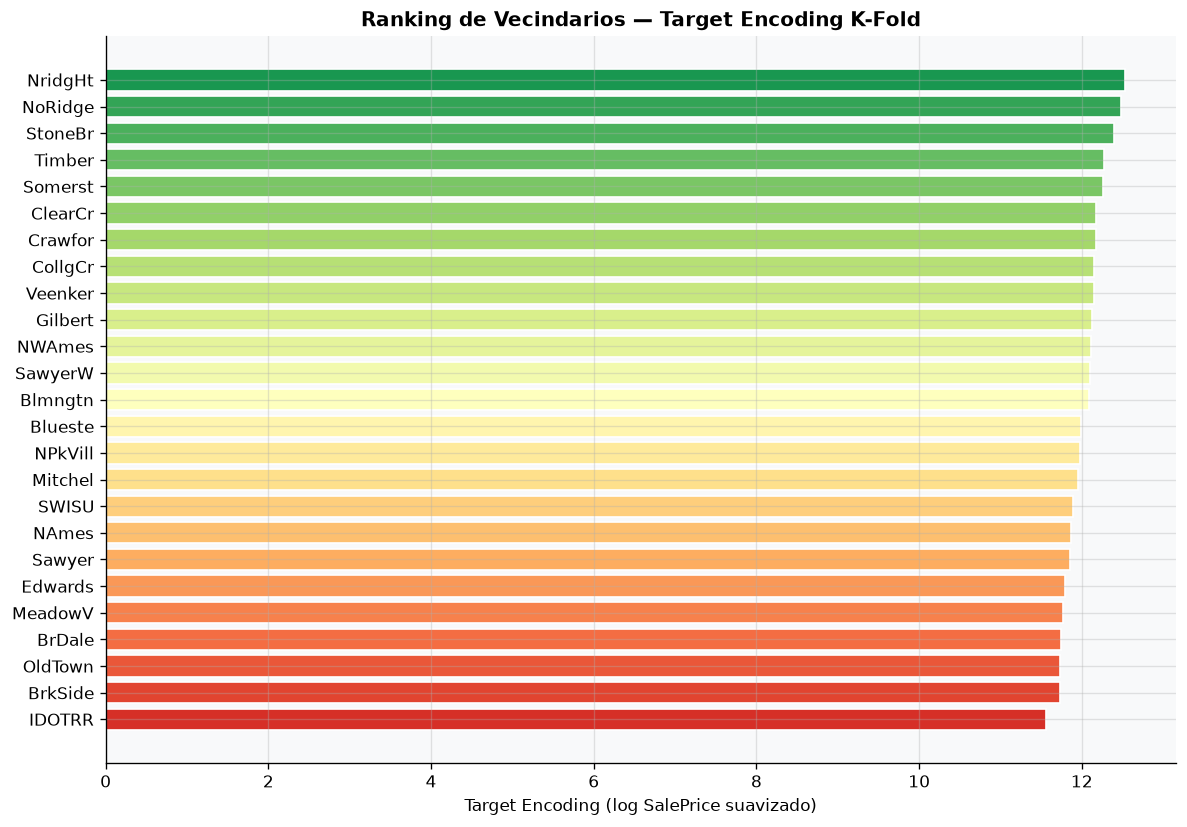

In [49]:
# ─── 8.1 TARGET ENCODING CON K-FOLD ────────────────────────────────────────
def kfold_target_encode(train_series, y_train, test_series, n_folds=5, smoothing=10):
    global_mean = y_train.mean()
    encoded_train = pd.Series(np.nan, index=train_series.index)
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)
    for tr_idx, val_idx in kf.split(train_series):
        fold_stats = y_train.iloc[tr_idx].groupby(train_series.iloc[tr_idx]).agg(['mean','count'])
        fold_stats['smoothed'] = ((fold_stats['mean'] * fold_stats['count'] + global_mean * smoothing)
                                   / (fold_stats['count'] + smoothing))
        encoded_train.iloc[val_idx] = train_series.iloc[val_idx].map(fold_stats['smoothed'])
    full_stats = y_train.groupby(train_series).agg(['mean','count'])
    full_stats['smoothed'] = ((full_stats['mean'] * full_stats['count'] + global_mean * smoothing)
                               / (full_stats['count'] + smoothing))
    encoded_test = test_series.map(full_stats['smoothed']).fillna(global_mean)
    return encoded_train.fillna(global_mean), encoded_test

# Aplicar a múltiples columnas
for col in ['Neighborhood','MSSubClass','MSZoning','SaleType','SaleCondition']:
    tr_s = all_data[col].astype(str).iloc[:ntrain]
    te_s = all_data[col].astype(str).iloc[ntrain:]
    enc_tr, enc_te = kfold_target_encode(tr_s, y, te_s)
    new_col = f'{col}_TargetEnc'
    all_data[new_col] = pd.concat([enc_tr, enc_te], axis=0).values
    r, _ = pearsonr(all_data[new_col].iloc[:ntrain], y)
    print(f'  {new_col:<35}  r = {r:+.4f}')

# Visualizar ranking de vecindarios
neigh_enc = all_data[['Neighborhood','Neighborhood_TargetEnc']].drop_duplicates('Neighborhood').sort_values('Neighborhood_TargetEnc')
fig, ax = plt.subplots(figsize=(10, 7))
colors_n = plt.cm.RdYlGn(np.linspace(0.1, 0.9, len(neigh_enc)))
ax.barh(neigh_enc['Neighborhood'], neigh_enc['Neighborhood_TargetEnc'], color=colors_n, edgecolor='white')
ax.set_xlabel('Target Encoding (log SalePrice suavizado)')
ax.set_title('Ranking de Vecindarios — Target Encoding K-Fold', fontweight='bold')
plt.tight_layout()
plt.savefig('fe_05_target_encoding.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 9 · Features Polinómicas y Transformaciones Log

In [50]:
# ─── 9.1 CUADRADOS Y LOG ────────────────────────────────────────────────────
for feat in ['OverallQual','GrLivArea','TotalSF','YearBuilt','TotalBathrooms']:
    all_data[f'{feat}_sq'] = all_data[feat] ** 2
    r, _ = pearsonr(all_data[f'{feat}_sq'].iloc[:ntrain], y)
    print(f'  {feat}_sq    r = {r:+.4f}')

print()
for feat in ['LotArea','GrLivArea','TotalSF','TotalBsmtSF','1stFlrSF']:
    all_data[f'log_{feat}'] = np.log1p(all_data[feat])
    r, _ = pearsonr(all_data[f'log_{feat}'].iloc[:ntrain], y)
    print(f'  log_{feat:<18}  r = {r:+.4f}')

  OverallQual_sq    r = +0.8155
  GrLivArea_sq    r = +0.6738
  TotalSF_sq    r = +0.7882
  YearBuilt_sq    r = +0.5911
  TotalBathrooms_sq    r = +0.6396

  log_LotArea             r = +0.4001
  log_GrLivArea           r = +0.7328
  log_TotalSF             r = +0.8148
  log_TotalBsmtSF         r = +0.3724
  log_1stFlrSF            r = +0.6110


---
## 10 · Validación Cuantitativa — ¿Qué features realmente ayudan?

In [51]:
# ─── 10.1 ENCODING COMPLETO Y EVALUACION ───────────────────────────────────
# Encoding ordinal restante
ord_cols_map = {
    'BsmtExposure': {'None':0,'No':1,'Mn':2,'Av':3,'Gd':4},
    'BsmtFinType1': {'None':0,'Unf':1,'LwQ':2,'Rec':3,'BLQ':4,'ALQ':5,'GLQ':6},
    'BsmtFinType2': {'None':0,'Unf':1,'LwQ':2,'Rec':3,'BLQ':4,'ALQ':5,'GLQ':6},
    'GarageFinish': {'None':0,'Unf':1,'RFn':2,'Fin':3},
    'Functional':   {'Sal':1,'Sev':2,'Maj2':3,'Maj1':4,'Mod':5,'Min2':6,'Min1':7,'Typ':8},
    'Fence':        {'None':0,'MnWw':1,'GdWo':2,'MnPrv':3,'GdPrv':4},
    'LandSlope':    {'Gtl':1,'Mod':2,'Sev':3},
    'LotShape':     {'IR3':1,'IR2':2,'IR1':3,'Reg':4},
    'PavedDrive':   {'N':0,'P':1,'Y':2},
}
for col, mapping in ord_cols_map.items():
    if col in all_data.columns:
        all_data[col] = all_data[col].map(mapping).fillna(0).astype(int)

# Drop baja varianza
for col in ['Utilities','Street']:
    if col in all_data.columns: all_data.drop(columns=col, inplace=True)

# OHE final
cat_final = all_data.select_dtypes('object').columns.tolist()
all_data_enc = pd.get_dummies(all_data, columns=cat_final, drop_first=False, dtype=int)

X_train_full = all_data_enc.iloc[:ntrain].fillna(0)
X_test_full  = all_data_enc.iloc[ntrain:].fillna(0)

print(f'Dataset con TODAS las features: {X_train_full.shape}')

# Evaluación: Ridge y Lasso
kf = KFold(n_splits=10, shuffle=True, random_state=42)

sc_fe = RobustScaler()
X_fe_scaled = sc_fe.fit_transform(X_train_full)

scores_ridge_fe = np.sqrt(-cross_val_score(Ridge(alpha=10), X_fe_scaled, y,
                           scoring='neg_mean_squared_error', cv=kf))
scores_lasso_fe = np.sqrt(-cross_val_score(Lasso(alpha=0.0003, max_iter=10000),
                           X_fe_scaled, y, scoring='neg_mean_squared_error', cv=kf))

mejora = (BASE_RMSLE - scores_ridge_fe.mean()) / BASE_RMSLE * 100

print('\n' + '=' * 60)
print('  IMPACTO DEL FEATURE ENGINEERING (10-fold CV)')
print('=' * 60)
print(f'  Ridge SIN FE:  {BASE_RMSLE:.5f}')
print(f'  Ridge CON FE:  {scores_ridge_fe.mean():.5f} ± {scores_ridge_fe.std():.5f}')
print(f'  Lasso CON FE:  {scores_lasso_fe.mean():.5f} ± {scores_lasso_fe.std():.5f}')
print(f'  Mejora Ridge:  {mejora:+.2f}%')
print('=' * 60)

Dataset con TODAS las features: (1456, 288)

  IMPACTO DEL FEATURE ENGINEERING (10-fold CV)
  Ridge SIN FE:  0.11291
  Ridge CON FE:  0.10977 ± 0.01297
  Lasso CON FE:  0.10877 ± 0.01265
  Mejora Ridge:  +2.78%


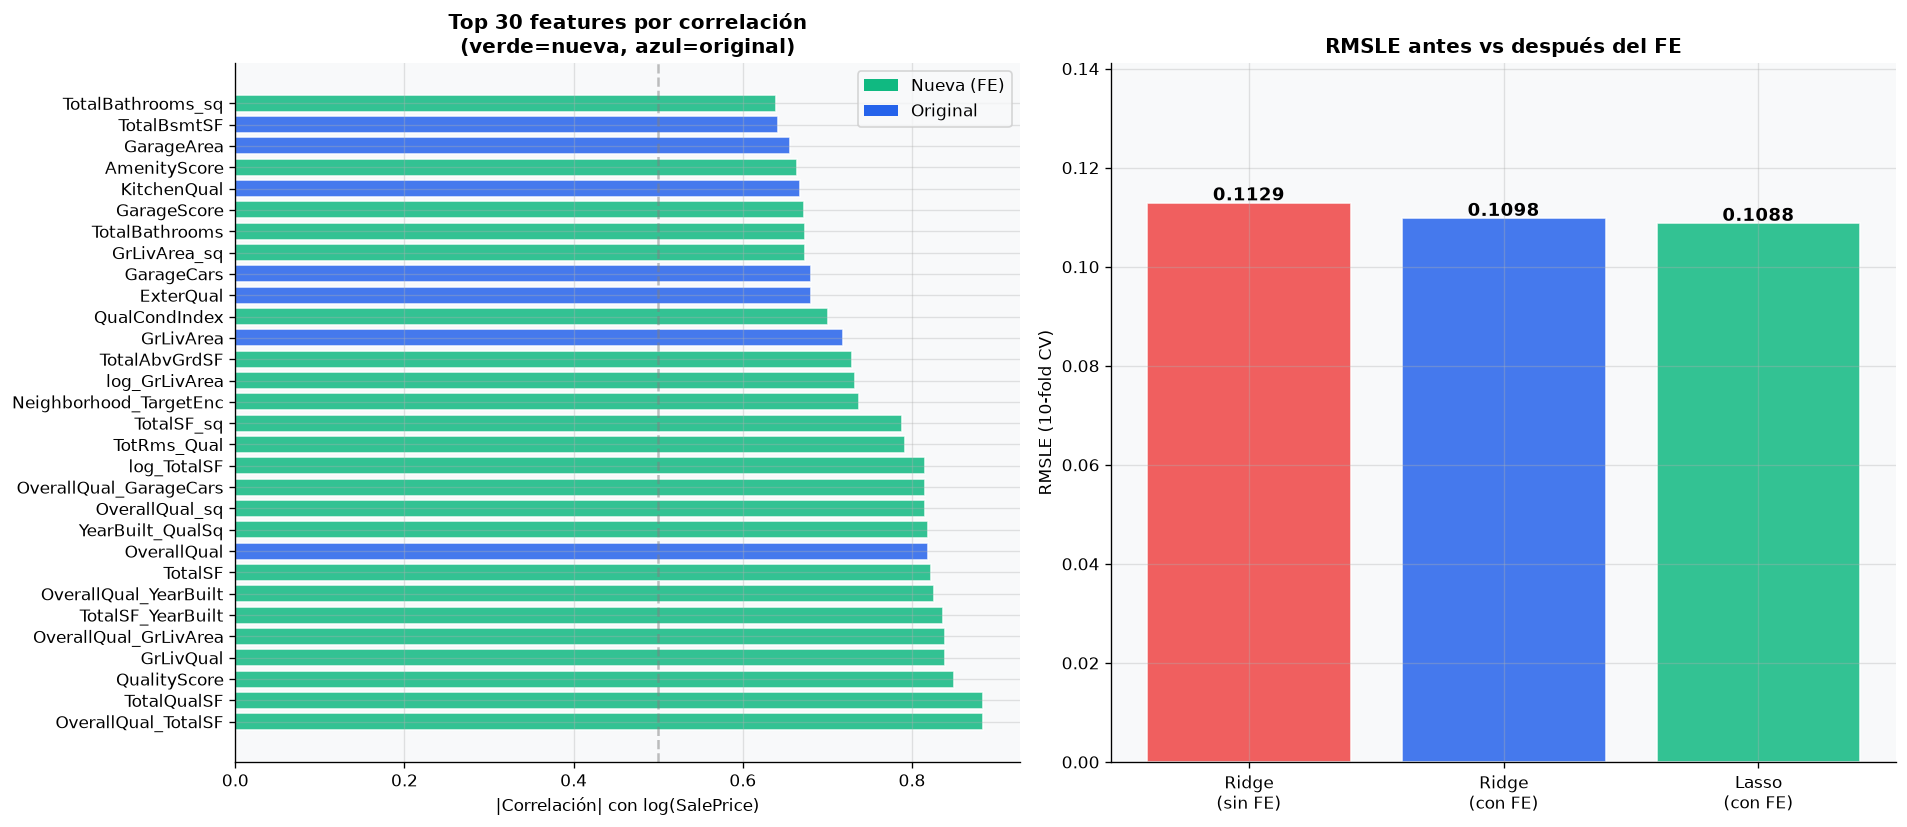


Features NUEVAS en el Top 30: 23/30
   ✅ OverallQual_TotalSF                  |r| = 0.8835
   ✅ TotalQualSF                          |r| = 0.8835
   ✅ QualityScore                         |r| = 0.8495
   ✅ GrLivQual                            |r| = 0.8387
   ✅ OverallQual_GrLivArea                |r| = 0.8387
   ✅ TotalSF_YearBuilt                    |r| = 0.8363
   ✅ OverallQual_YearBuilt                |r| = 0.8260
   ✅ TotalSF                              |r| = 0.8220
   ✅ YearBuilt_QualSq                     |r| = 0.8187
   ✅ OverallQual_sq                       |r| = 0.8155
   ✅ OverallQual_GarageCars               |r| = 0.8152
   ✅ log_TotalSF                          |r| = 0.8148
   ✅ TotRms_Qual                          |r| = 0.7916
   ✅ TotalSF_sq                           |r| = 0.7882
   ✅ Neighborhood_TargetEnc               |r| = 0.7369
   ✅ log_GrLivArea                        |r| = 0.7328
   ✅ TotalAbvGrdSF                        |r| = 0.7294
   ✅ QualCondIndex          

In [52]:
# ─── 10.2 TOP 30 FEATURES POR CORRELACION ──────────────────────────────────
original_cols = set(train_raw.columns) - {'SalePrice','Id'}
correlations = X_train_full.apply(lambda col: abs(col.corr(y))).sort_values(ascending=False)
top30 = correlations.head(30)
all_new_feats = set(X_train_full.columns) - original_cols
new_in_top30  = [c for c in top30.index if c in all_new_feats]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Gráfico 1: top 30 correlaciones
ax = axes[0]
colors_top = [COLOR_SUCCESS if c in all_new_feats else COLOR_MAIN for c in top30.index]
ax.barh(top30.index, top30.values, color=colors_top, alpha=0.85, edgecolor='white')
ax.set_xlabel('|Correlación| con log(SalePrice)')
ax.set_title('Top 30 features por correlación\n(verde=nueva, azul=original)', fontweight='bold')
ax.axvline(0.5, color='gray', linestyle='--', alpha=0.5)
legend_elements = [Patch(facecolor=COLOR_SUCCESS, label='Nueva (FE)'),
                   Patch(facecolor=COLOR_MAIN,    label='Original')]
ax.legend(handles=legend_elements)

# Gráfico 2: RMSLE comparativo
ax = axes[1]
models  = ['Ridge\n(sin FE)', 'Ridge\n(con FE)', 'Lasso\n(con FE)']
means   = [BASE_RMSLE, scores_ridge_fe.mean(), scores_lasso_fe.mean()]
bar_clr = [COLOR_DANGER, COLOR_MAIN, COLOR_SUCCESS]
bars = ax.bar(models, means, color=bar_clr, alpha=0.85, edgecolor='white')
for bar, m in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0005,
            f'{m:.4f}', ha='center', fontsize=11, fontweight='bold')
ax.set_ylabel('RMSLE (10-fold CV)')
ax.set_title('RMSLE antes vs después del FE', fontweight='bold')
ax.set_ylim(0, max(means) * 1.25)

plt.tight_layout()
plt.savefig('fe_06_resumen.png', bbox_inches='tight', dpi=120)
plt.show()

print(f'\nFeatures NUEVAS en el Top 30: {len(new_in_top30)}/30')
for f in new_in_top30:
    print(f'   ✅ {f:<35}  |r| = {top30[f]:.4f}')

---
## 11 · Guardado de artefactos

In [59]:
# ─── 11.1 GUARDAR DATASETS ENRIQUECIDOS ─────────────────────────────────────
pd.options.future.infer_string = False

import os

# Para modelos tree-based (sin scaling)
X_train_full.to_parquet('X_train_FE.parquet', index=False, engine='fastparquet')
X_test_full.to_parquet( 'X_test_FE.parquet',  index=False, engine='fastparquet')

# Para modelos lineales (con scaling)
sc_final = RobustScaler()
X_train_FE_scaled = sc_final.fit_transform(X_train_full)
X_test_FE_scaled  = sc_final.transform(X_test_full)

np.save('X_train_FE_scaled.npy', X_train_FE_scaled)
np.save('X_test_FE_scaled.npy',  X_test_FE_scaled)
np.save('y_train.npy',           y.values)

joblib.dump(sc_final, 'scaler_FE.pkl')

with open('feature_names_FE.txt', 'w') as f:
    f.write('\n'.join(X_train_full.columns.tolist()))

with open('new_features_FE.txt', 'w') as f:
    for feat in sorted(all_new_feats):
        if feat in X_train_full.columns:
            f.write(feat + '\n')

print('✅ Artefactos guardados:')
files = ['X_train_FE.parquet','X_test_FE.parquet','X_train_FE_scaled.npy',
         'X_test_FE_scaled.npy','y_train.npy','scaler_FE.pkl',
         'feature_names_FE.txt','new_features_FE.txt']
for fname in files:
    if os.path.exists(fname):
        print(f'   📄 {fname:<30} ({os.path.getsize(fname)/1024:.1f} KB)')

print('\n' + '=' * 65)
print('  RESUMEN EJECUTIVO — FEATURE ENGINEERING')
print('=' * 65)
print(f'''
  Dataset original:  {ntrain} filas × ~80 features
  Dataset con FE:    {ntrain} filas × {X_train_full.shape[1]} features

  RMSLE sin FE (Ridge 10-fold): {BASE_RMSLE:.5f}
  RMSLE con FE (Ridge 10-fold): {scores_ridge_fe.mean():.5f}
  RMSLE con FE (Lasso 10-fold): {scores_lasso_fe.mean():.5f}
  Mejora:                        {mejora:+.2f}%
  Features nuevas en Top-30:     {len(new_in_top30)}/30

  Siguiente paso → Notebook 4: XGBoost + LightGBM + Optuna + Ensemble
  Objetivo final: RMSLE < 0.11
''')
print('=' * 65)

✅ Artefactos guardados:
   📄 X_train_FE.parquet             (537.1 KB)
   📄 X_test_FE.parquet              (509.3 KB)
   📄 X_train_FE_scaled.npy          (3276.1 KB)
   📄 X_test_FE_scaled.npy           (3282.9 KB)
   📄 y_train.npy                    (11.5 KB)
   📄 scaler_FE.pkl                  (10.1 KB)
   📄 feature_names_FE.txt           (4.6 KB)
   📄 new_features_FE.txt            (4.0 KB)

  RESUMEN EJECUTIVO — FEATURE ENGINEERING

  Dataset original:  1456 filas × ~80 features
  Dataset con FE:    1456 filas × 288 features

  RMSLE sin FE (Ridge 10-fold): 0.11291
  RMSLE con FE (Ridge 10-fold): 0.10977
  RMSLE con FE (Lasso 10-fold): 0.10877
  Mejora:                        +2.78%
  Features nuevas en Top-30:     23/30

  Siguiente paso → Notebook 4: XGBoost + LightGBM + Optuna + Ensemble
  Objetivo final: RMSLE < 0.11

